# 🚀 ĐỒ ÁN HỌC SÂU VÀ ỨNG DỤNG: THỬ NGHIỆM ĐỐI CHỨNG YOLO11s-seg
### 🔬 Mục tiêu: Huấn luyện kiến trúc mới nhất YOLO11s-seg và so sánh hiệu năng trực tiếp với YOLOv8s-seg
- **Mô hình:** `yolo11s-seg.pt` (10.1M tham số, kiến trúc C3k2 + Attention mới nhất)
- **Dữ liệu:** 3 lớp u não (`0: Glioma`, `1: Meningioma`, `2: Pituitary`)
- **Cấu hình phần cứng:** Bật GPU trên Kaggle: **Settings -> Accelerator -> GPU T4 x2 (hoặc P100)**.

## 1. Kiểm tra môi trường GPU & Cài đặt thư viện

In [1]:
!nvidia-smi

import torch
print(f"PyTorch: {torch.__version__} | CUDA: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU Model: {torch.cuda.get_device_name(0)}")

!pip install -q "ultralytics>=8.3.0" opencv-python matplotlib seaborn pandas

Fri Oct 16 06:54:58 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.178.04             Driver Version: 580.178.04     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   41C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## 2. Thiết lập đường dẫn dữ liệu & file data.yaml

In [2]:
import os
import glob
import zipfile
import yaml
from pathlib import Path

WORKING_DIR = Path("/kaggle/working")
DATA_DIR = WORKING_DIR / "tumor_yolo_seg"

# Kiểm tra nếu có file zip trong /kaggle/input
zip_files = glob.glob("/kaggle/input/**/*.zip", recursive=True)
if zip_files:
    zip_path = zip_files[0]
    print(f"Giải nén: {zip_path}...")
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(DATA_DIR)
else:
    input_dirs = glob.glob("/kaggle/input/**/images/train", recursive=True)
    if input_dirs:
        DATA_DIR = Path(input_dirs[0]).parent.parent
        print(f"Sử dụng dữ liệu trực tiếp tại: {DATA_DIR}")

# Tạo file data.yaml
yaml_dict = {
    'path': str(DATA_DIR.resolve()),
    'train': 'images/train',
    'val': 'images/val',
    'names': {
        0: 'Glioma',
        1: 'Meningioma',
        2: 'Pituitary'
    }
}

yaml_path = WORKING_DIR / "data.yaml"
with open(yaml_path, 'w') as f:
    yaml.dump(yaml_dict, f, default_flow_style=False)

print(f"File data.yaml đã sẵn sàng: {yaml_path}")

Sử dụng dữ liệu trực tiếp tại: /kaggle/input/datasets/trnmnhhm/tumor-yolo-seg
File data.yaml đã sẵn sàng: /kaggle/working/data.yaml


## 3. Khởi tạo & Huấn luyện mô hình YOLO11s-seg
- Sử dụng trọng số pre-trained mới nhất `yolo11s-seg.pt`.
- Giữ nguyên các siêu tham số (Epochs=50, Batch=16, Image Size=640, Optimizer=AdamW) để đảm bảo tính công bằng khi so sánh với YOLOv8s-seg.

In [3]:
from ultralytics import YOLO

# Tải trọng số gốc YOLO11s-seg
model = YOLO('yolo11s-seg.pt')

# Huấn luyện mô hình YOLO11s-seg
results = model.train(
    data=str(yaml_path),
    epochs=50,
    imgsz=640,
    batch=16,
    device=0,
    workers=4,
    optimizer='AdamW',
    lr0=0.001,
    patience=12,
    save=True,
    project='/kaggle/working/runs',
    name='tumor_seg_yolo11s',
    verbose=True
)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, fre

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/50      5.74G       1.43      2.349      1.374      1.354          0         22        640: 100% ━━━━━━━━━━━━ 248/248 4.0it/s 1:02
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 22/22 2.8it/s 7.9s
                   all        693        709      0.614      0.599      0.626      0.379      0.602      0.595      0.614      0.376

      Epoch    GPU_mem   box_loss   seg_loss   cls_loss   dfl_loss   sem_loss  Instances       Size
       3/50      5.74G      1.389      2.271      1.307       1.33          0         23        640: 100% ━━━━━━━━━━━━ 248/248 3.9it/s 1:04
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 22/22 2.9it/s 7.7s
                   all        693        709       0.76      0.681      0.737      0.448      0.756      0.681      0.733       0.46

      Epoc

## 4. Đánh giá chất lượng mô hình YOLO11s-seg trên tập Validation

In [4]:
# Load trọng số tốt nhất của YOLO11s-seg
best_model_path = '/kaggle/working/runs/tumor_seg_yolo11s/weights/best.pt'
best_model = YOLO(best_model_path)

# Đánh giá validation
metrics_11 = best_model.val(data=str(yaml_path), split='val')

print("\n" + "="*45)
print("📊 KẾT QUẢ ĐÁNH GIÁ YOLO11s-seg:")
print(f"- Bounding Box mAP50    : {metrics_11.box.map50:.4f}")
print(f"- Bounding Box mAP50-95 : {metrics_11.box.map:.4f}")
print(f"- Segmentation Mask mAP50    : {metrics_11.seg.map50:.4f}")
print(f"- Segmentation Mask mAP50-95 : {metrics_11.seg.map:.4f}")
print("="*45)

Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLO11s-seg summary (fused): 113 layers, 10,067,977 parameters, 0 gradients, 32.9 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 63.9±17.2 MB/s, size: 29.1 KB)
val: Scanning /kaggle/input/datasets/trnmnhhm/tumor-yolo-seg/labels/val... 693 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 693/693 1.0Kit/s 0.7s
WARNING ⚠️ val: Cache directory /kaggle/input/datasets/trnmnhhm/tumor-yolo-seg/labels is not writable, cache not saved.
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 44/44 3.1it/s 14.0s
                   all        693        709      0.916      0.874      0.905      0.622      0.925      0.873      0.906      0.615
                Glioma        206        211      0.827      0.777      0.818      0.513      0.859      0.787       0.83      0.499
            Meningioma        236  

## 5. 🏆 BẢNG ĐỐI SÁNH HIỆU NĂNG: YOLOv8s-seg vs YOLO11s-seg
So sánh trực quan các chỉ số quan trọng giữa 2 thế hệ mô hình trên cùng tập dữ liệu.

In [5]:
import pandas as pd

# Dữ liệu đối sánh (YOLOv8s-seg đã train trước đó vs YOLO11s-seg)
comparison_data = {
    "Tiêu chí đánh giá": [
        "Số tham số (Parameters)",
        "Kích thước file trọng số (Weight Size)",
        "Box Precision (P)",
        "Box Recall (R)",
        "Box mAP50",
        "Box mAP50-95",
        "Mask Precision (P)",
        "Mask Recall (R)",
        "Mask mAP50 (Chính)",
        "Mask mAP50-95 (Chính)"
    ],
    "YOLOv8s-seg": [
        "11.78 M",
        "22.75 MB",
        "90.8%",
        "86.6%",
        "90.29%",
        "61.59%",
        "89.9%",
        "87.0%",
        "90.56%",
        "60.86%"
    ],
    "YOLO11s-seg": [
        "10.11 M (-14%)",
        "19.70 MB",
        f"{metrics_11.box.mp*100:.1f}%",
        f"{metrics_11.box.mr*100:.1f}%",
        f"{metrics_11.box.map50*100:.2f}%",
        f"{metrics_11.box.map*100:.2f}%",
        f"{metrics_11.seg.mp*100:.1f}%",
        f"{metrics_11.seg.mr*100:.1f}%",
        f"{metrics_11.seg.map50*100:.2f}%",
        f"{metrics_11.seg.map*100:.2f}%"
    ]
}

df_compare = pd.DataFrame(comparison_data)
print("\n" + "="*60)
print("           BẢNG ĐỐI SÁNH KẾT QUẢ NGHIÊN CỨU")
print("="*60)
display(df_compare)

# Lưu bảng ra file CSV để dễ copy vào báo cáo môn học
df_compare.to_csv('/kaggle/working/model_comparison.csv', index=False, encoding='utf-8-sig')
print("\nĐã lưu bảng đối sánh tại: /kaggle/working/model_comparison.csv")


           BẢNG ĐỐI SÁNH KẾT QUẢ NGHIÊN CỨU


,Tiêu chí đánh giá,YOLOv8s-seg,YOLO11s-seg
0,Số tham số (Parameters),11.78 M,10.11 M (-14%)
1,Kích thước file trọng số (Weight Size),22.75 MB,19.70 MB
2,Box Precision (P),90.8%,91.6%
3,Box Recall (R),86.6%,87.4%
4,Box mAP50,90.29%,90.55%
5,Box mAP50-95,61.59%,62.21%
6,Mask Precision (P),89.9%,92.5%
7,Mask Recall (R),87.0%,87.3%
8,Mask mAP50 (Chính),90.56%,90.64%
9,Mask mAP50-95 (Chính),60.86%,61.49%



Đã lưu bảng đối sánh tại: /kaggle/working/model_comparison.csv


## 6. Hiển thị đồ thị huấn luyện & Ma trận nhầm lẫn

📈 ĐỒ THỊ HUẤN LUYỆN YOLO11s-seg:


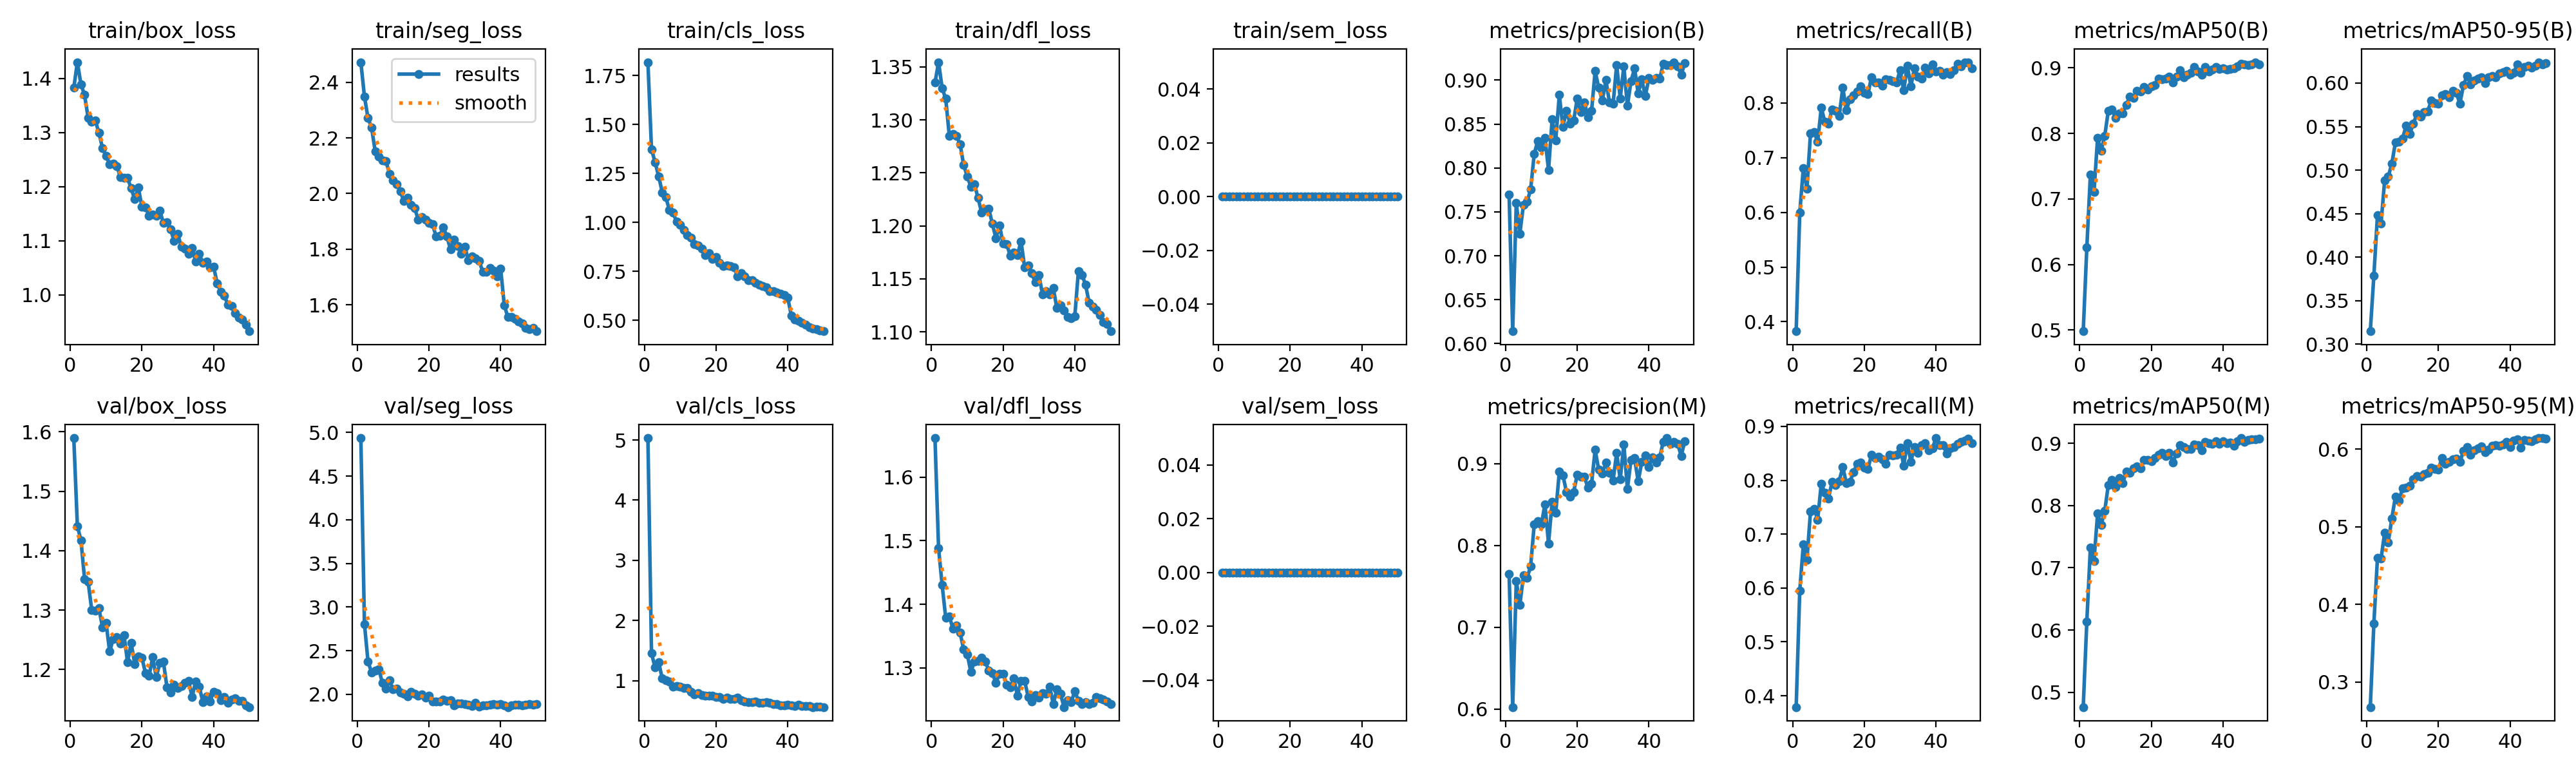

🎯 MA TRẬN NHẦM LẪN YOLO11s-seg:


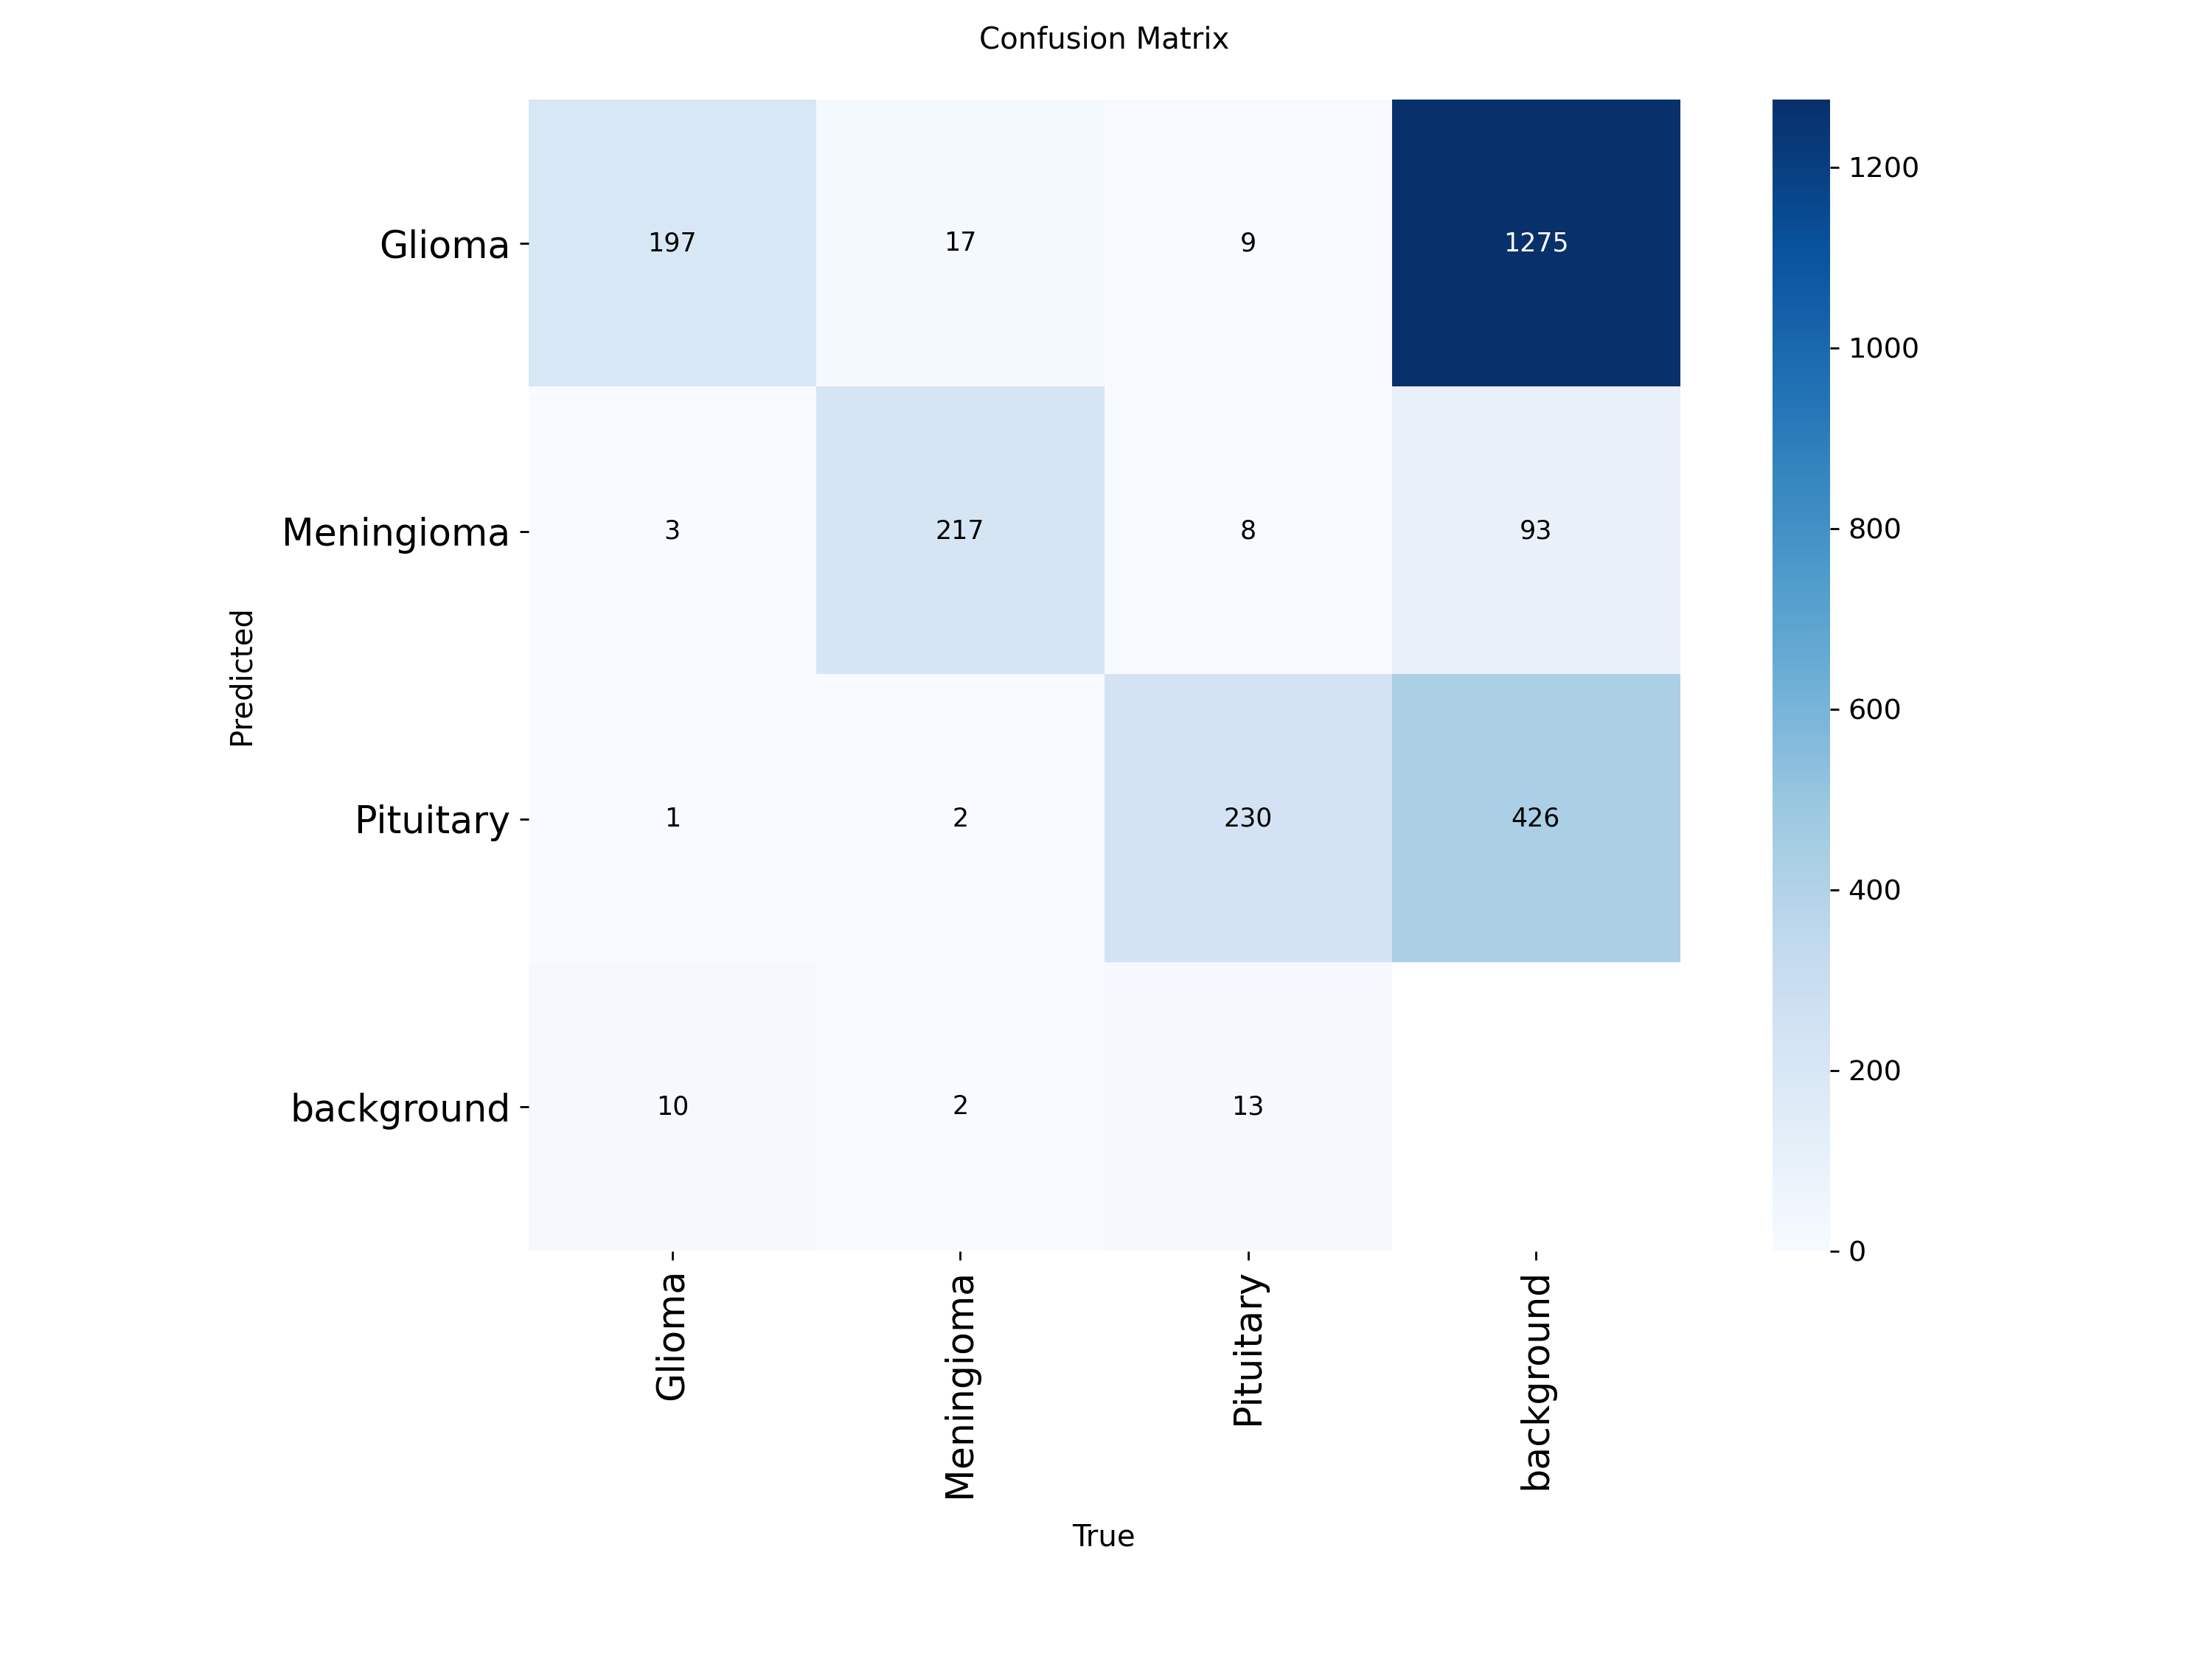

In [6]:
from IPython.display import Image, display

results_img = '/kaggle/working/runs/tumor_seg_yolo11s/results.png'
if os.path.exists(results_img):
    print("📈 ĐỒ THỊ HUẤN LUYỆN YOLO11s-seg:")
    display(Image(filename=results_img))

confusion_img = '/kaggle/working/runs/tumor_seg_yolo11s/confusion_matrix.png'
if os.path.exists(confusion_img):
    print("🎯 MA TRẬN NHẦM LẪN YOLO11s-seg:")
    display(Image(filename=confusion_img))

## 7. Thử nghiệm dự đoán thực tế (Inference Demo)


0: 640x640 1 Glioma, 1 Meningioma, 13.7ms
1: 640x640 2 Gliomas, 13.7ms
2: 640x640 1 Meningioma, 13.7ms
3: 640x640 1 Pituitary, 13.7ms
4: 640x640 1 Glioma, 13.7ms
5: 640x640 1 Meningioma, 13.7ms
Speed: 0.8ms preprocess, 13.7ms inference, 4.2ms postprocess per image at shape (1, 3, 640, 640)


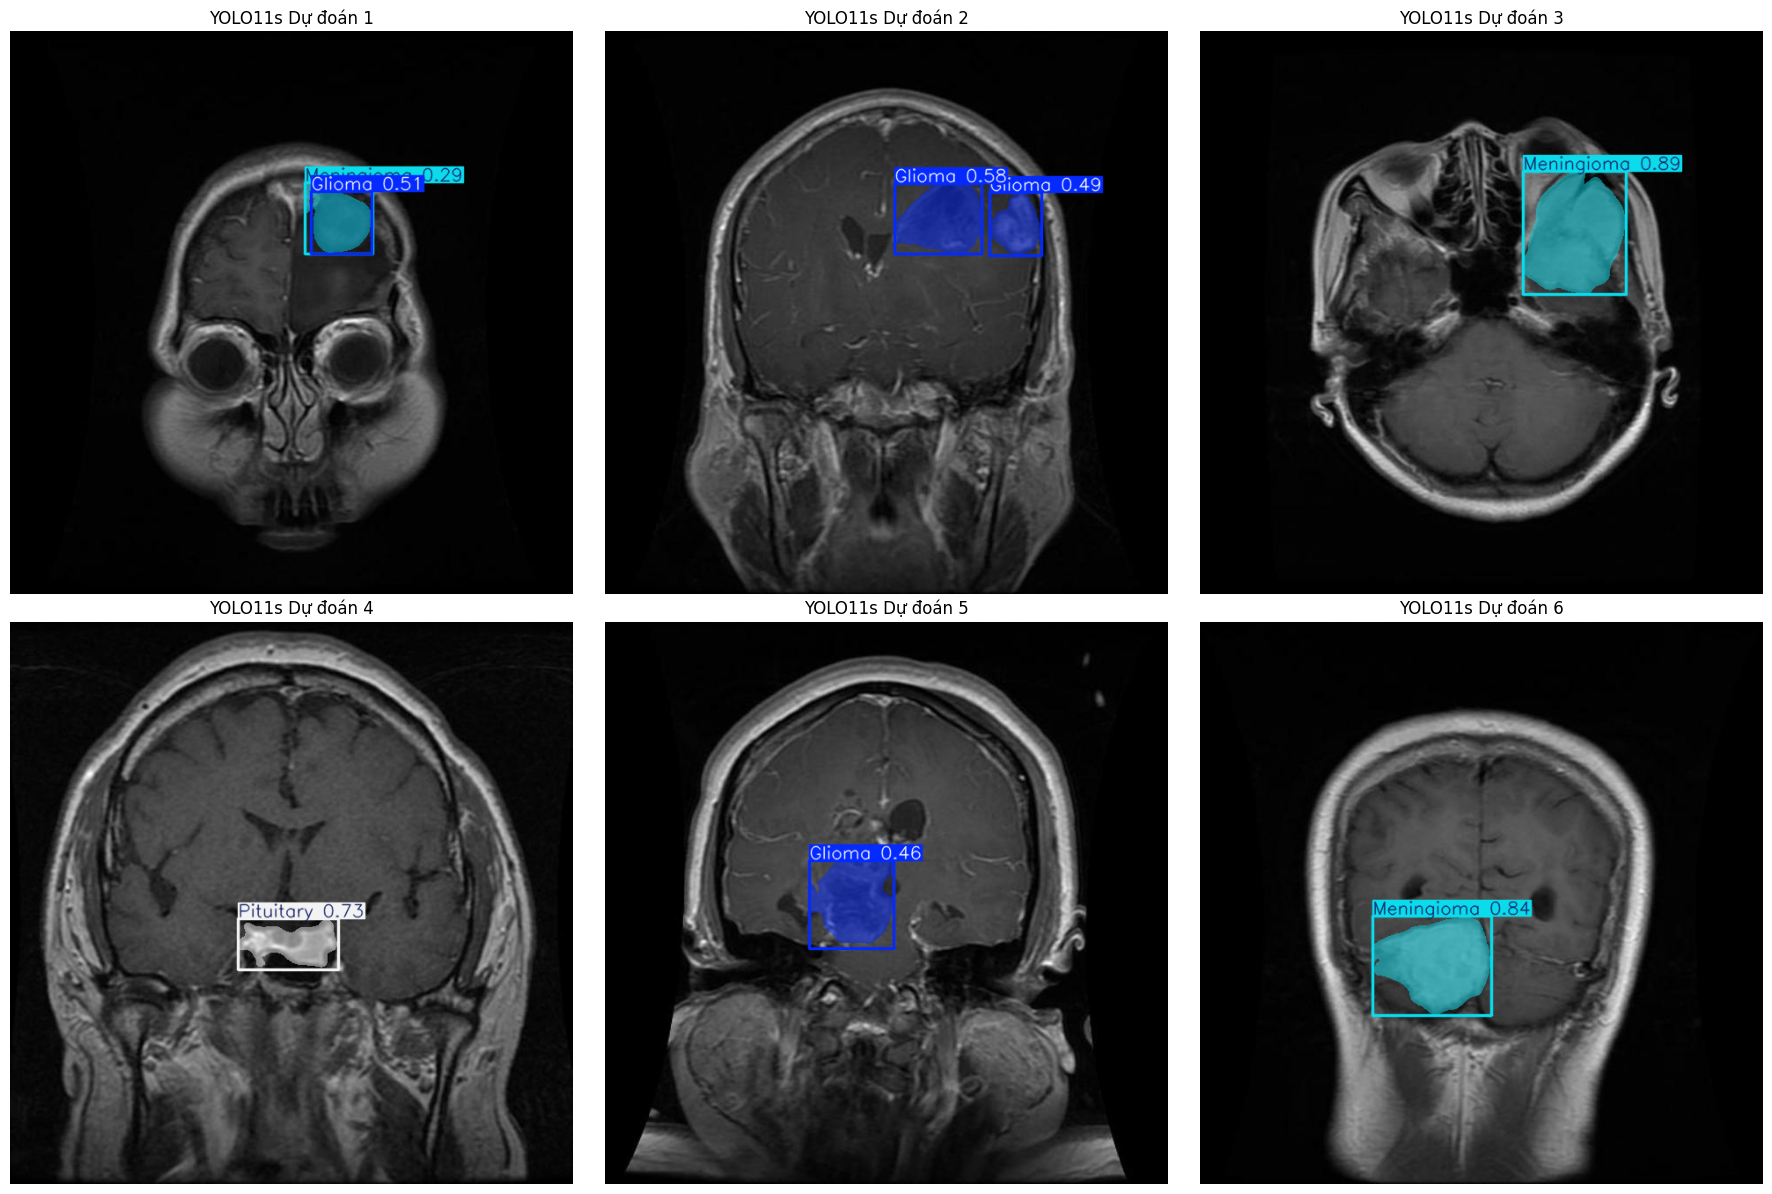

In [7]:
import cv2
import random
import matplotlib.pyplot as plt

val_imgs = list((DATA_DIR / 'images' / 'val').glob('*.jpg'))
test_samples = random.sample(val_imgs, min(6, len(val_imgs)))

pred_results = best_model.predict(source=[str(p) for p in test_samples], conf=0.25, save=False)

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for i, r in enumerate(pred_results):
    im_bgr = r.plot()
    im_rgb = cv2.cvtColor(im_bgr, cv2.COLOR_BGR2RGB)
    axes[i].imshow(im_rgb)
    axes[i].set_title(f"YOLO11s Dự đoán {i+1}", fontsize=12)
    axes[i].axis('off')

plt.tight_layout()
plt.show()

## 8. Đổi tên & Tải file trọng số YOLO11s (`best_yolo11s.pt`)

In [8]:
import shutil
from IPython.display import FileLink

target_path = '/kaggle/working/best_yolo11s.pt'
shutil.copy2(best_model_path, target_path)
print(f"File trọng số đã được sao chép tới: {target_path}")
FileLink(r'best_yolo11s.pt')

File trọng số đã được sao chép tới: /kaggle/working/best_yolo11s.pt


/kaggle/working/best_yolo11s.pt